# The twelve sectors, one at a time

The Earth4All model is twelve sectors wired together. Each of them can also be
run on its own: the variables the other eleven would have given it are read from
tabulated trajectories of a full run, so a sector can be looked at, and changed,
without carrying the whole model along.

This notebook draws the figure of every sector, then shows how to find what a
sector holds and to draw something else from it. The same figures are rendered
to `figures/sectors/` by `python scripts/render_figures.py`.

In [1]:
import matplotlib.pyplot as plt

import earth4all

earth4all.sector_names()

['climate',
 'demand',
 'energy',
 'finance',
 'foodland',
 'inventory',
 'labourmarket',
 'other',
 'output',
 'population',
 'public',
 'wellbeing']

Each figure below runs its sector over 1980–2100 and draws the variables the
Julia package puts on it. Every one is a `fig_*` function, and the vertical axes
are asked for explicitly — some sectors hide them by default.

## Climate

Warming, the gases behind it, and the ice left.

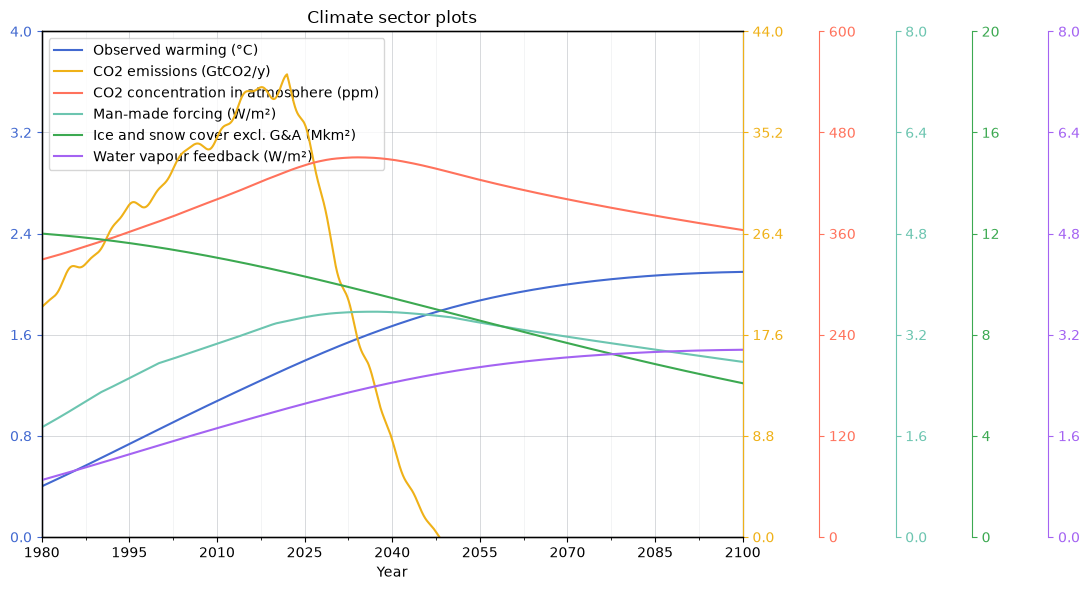

In [2]:
earth4all.climate.fig_cli(showaxis=True);

## Demand

How output is split between consumption, savings and the state, and how much debt households and governments carry.

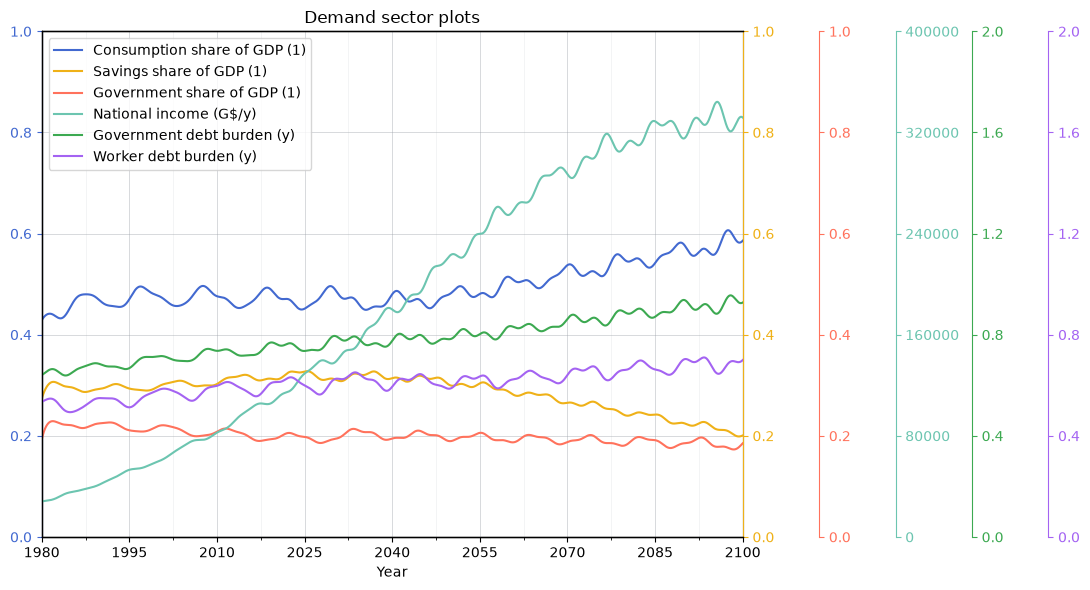

In [3]:
earth4all.demand.fig_dem(showaxis=True);

## Energy

The cost of the energy the world uses.

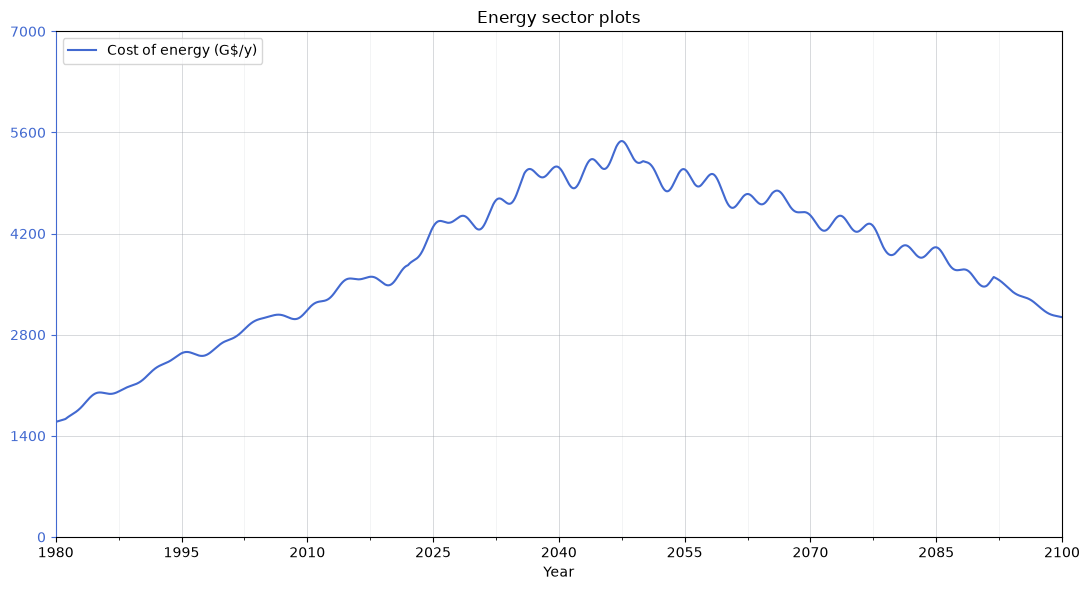

In [4]:
earth4all.energy.fig_en(showaxis=True);

## Finance

The signal rate the central bank sets and the borrowing costs that follow it, over the two decades around 2020.

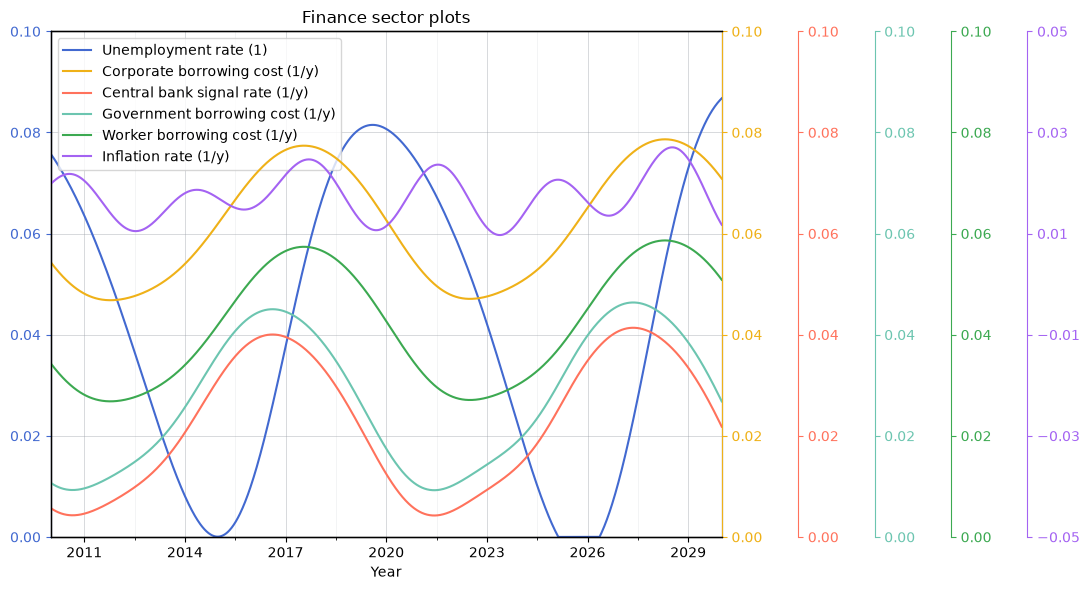

In [5]:
earth4all.finance.fig_fin(showaxis=True);

## Food and land

Cropland, what is grown on it, the fertiliser it takes, and the land left to regenerate.

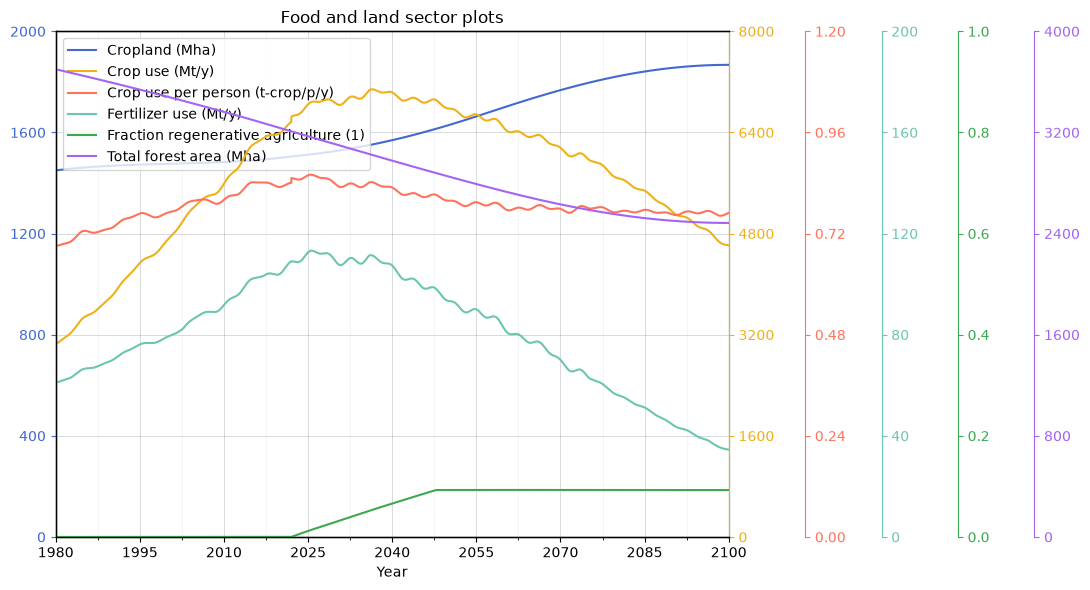

In [6]:
earth4all.foodland.fig_fl(showaxis=True);

## Inventory

Stocks against desired stocks, and the inflation that comes of the gap.

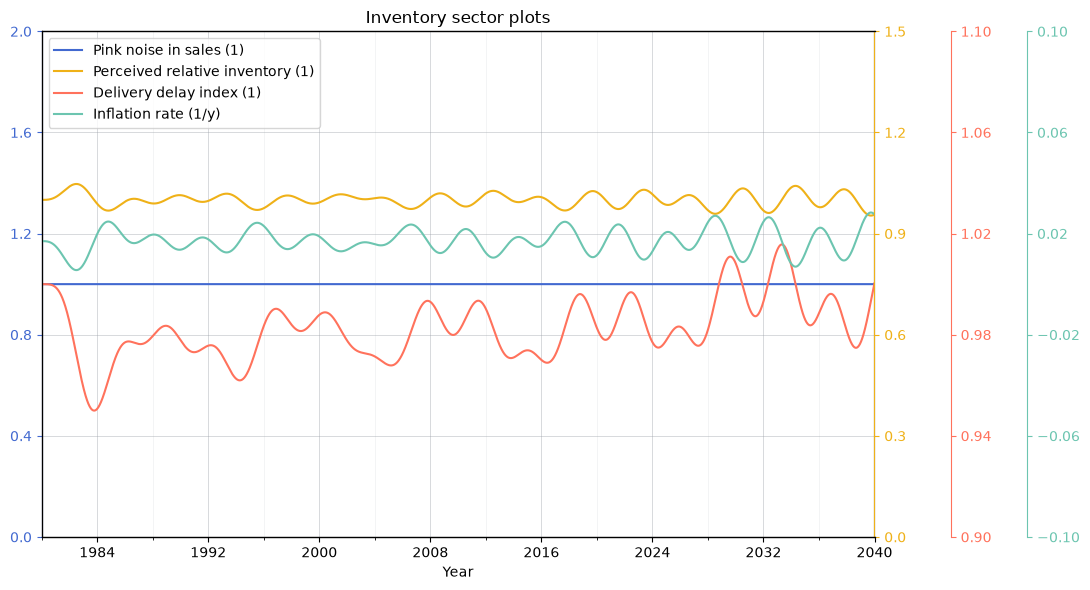

In [7]:
earth4all.inventory.fig_inv(showaxis=True);

## Labour market

The size of the workforce, its share of output, and unemployment.

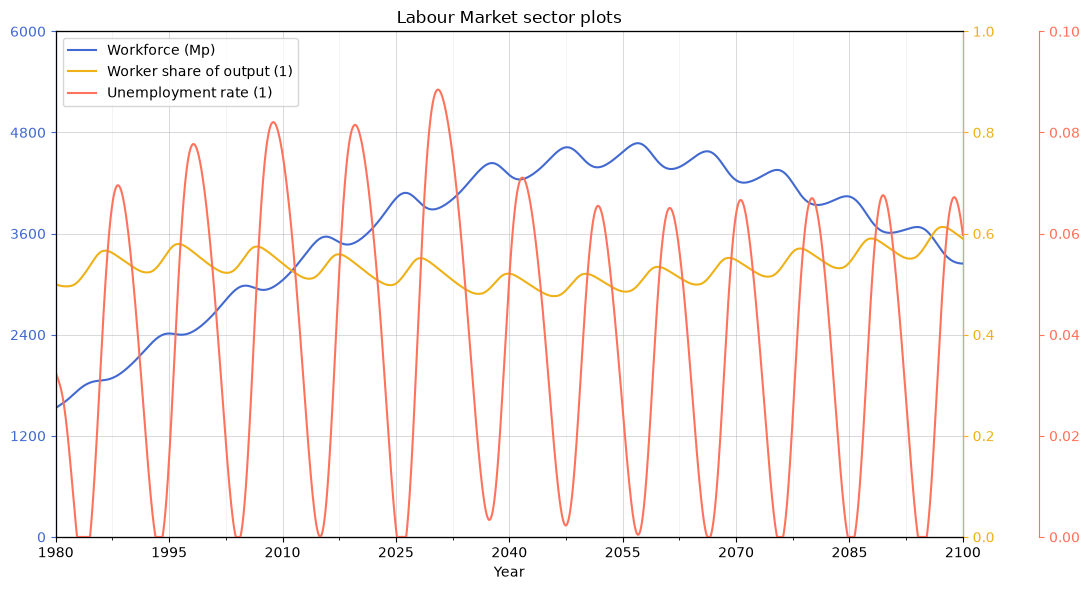

In [8]:
earth4all.labourmarket.fig_lab(showaxis=True);

## Other

The cost of the turnarounds, the people below the poverty line, and the growth of output per person.

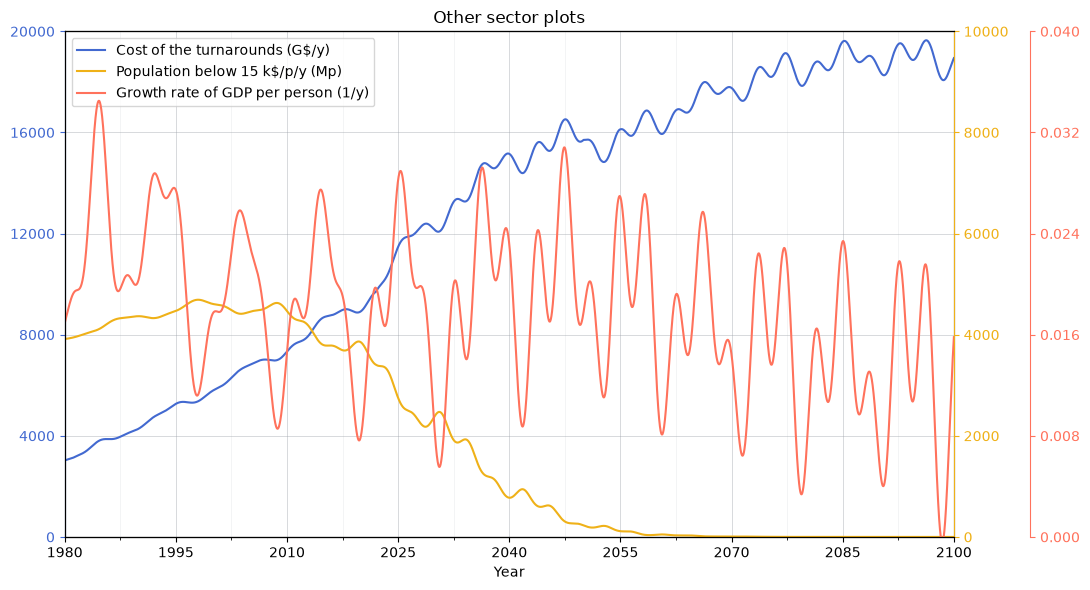

In [9]:
earth4all.other.fig_oth(showaxis=True);

## Output

The capital stock in private and public hands, and the output it yields.

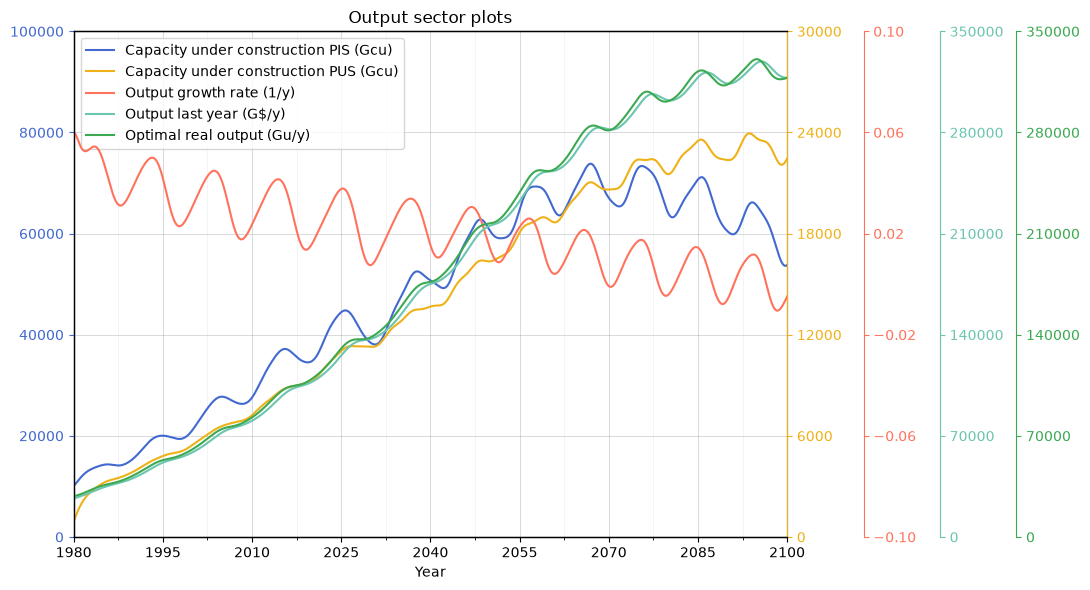

In [10]:
earth4all.output.fig_out(showaxis=True);

## Population

Births, life expectancy past sixty, and the population that results.

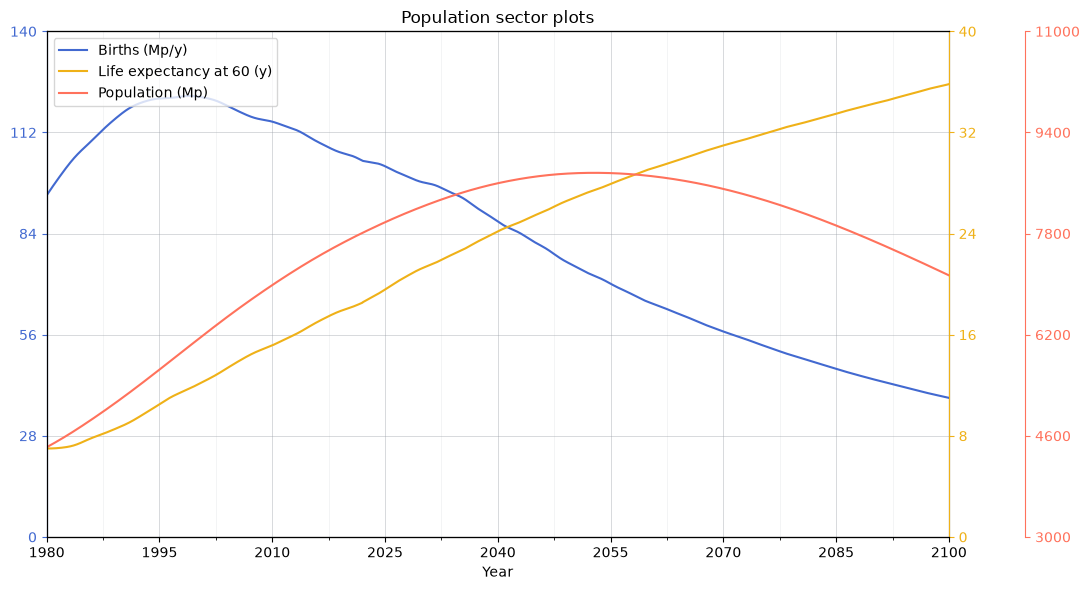

In [11]:
earth4all.population.fig_pop(showaxis=True);

## Public

Public spending, the tax that funds it, and the productivity it buys.

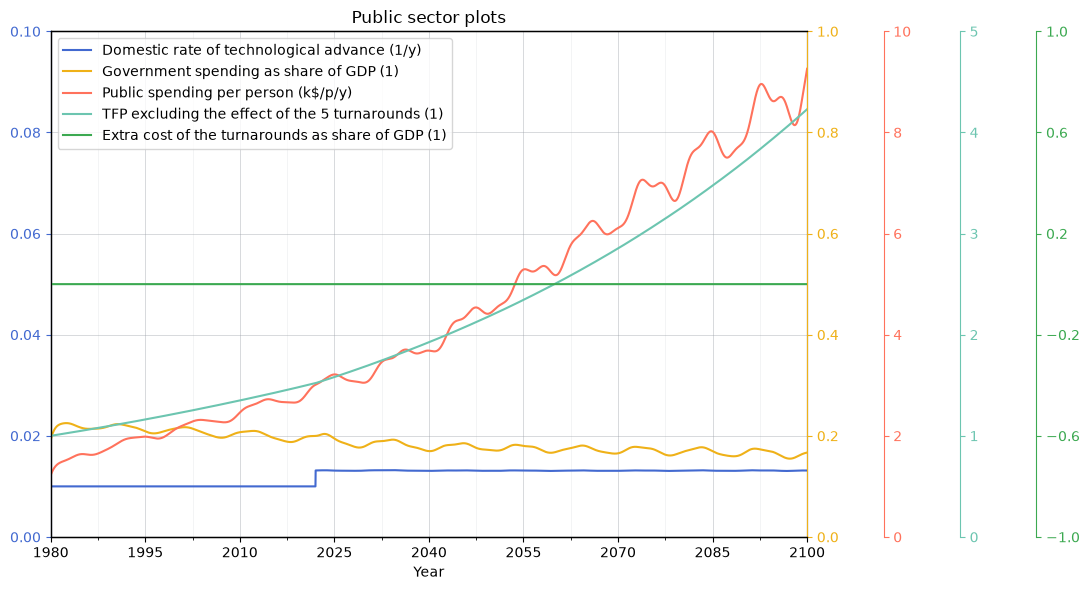

In [12]:
earth4all.public.fig_pub(showaxis=True);

## Wellbeing

The average wellbeing index, which the whole model is built to explain.

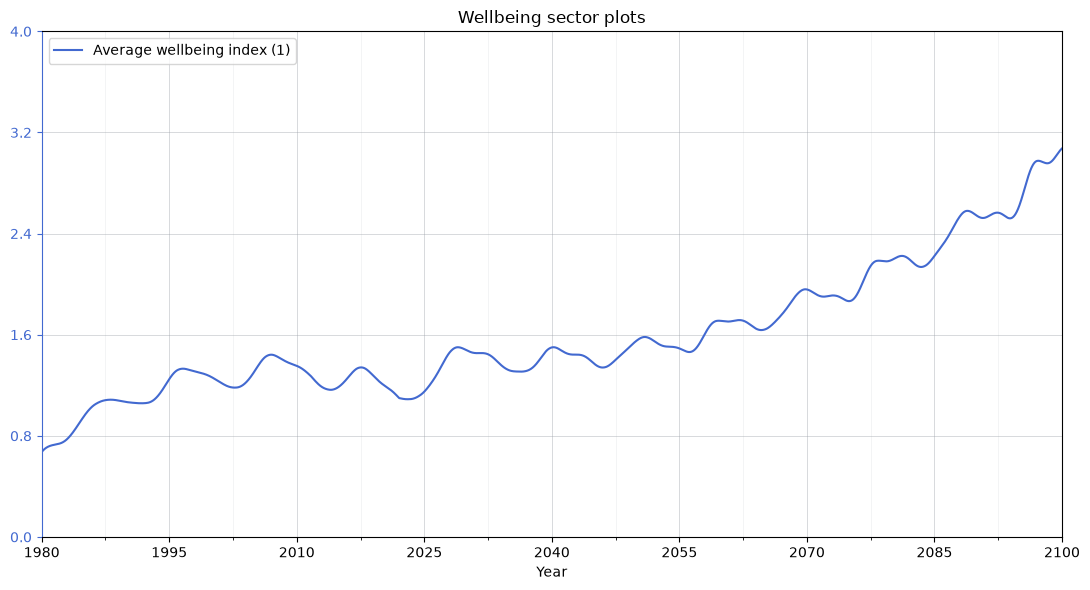

In [13]:
earth4all.wellbeing.fig_wb(showaxis=True);

## Drawing something else

A sector system knows every variable it declares, with the name it carries in
Vensim. That is the quickest way to find what else there is to look at.

In [14]:
foodland = earth4all.foodland.foodland()

for variable in foodland.declared_variables:
    if variable.description and variable.description.endswith("Mha"):
        print(f"{variable.name:8s} {variable.description}")

BALA     BArren LAnd Mha
CRLA     CRopLAnd Mha
FOLA     FOrestry LAnd Mha
GRLA     GRazing LAnd Mha
IUL      Indicated Urban Land Mha
RAA      Regenerative Agriculture Area Mha
TFA      Total Forest Area Mha
URLA     URban LAnd Mha


Any of them can go on a figure of your own. `plotvariables` takes
`(variable, lowest, highest, label)` tuples, one per vertical axis.

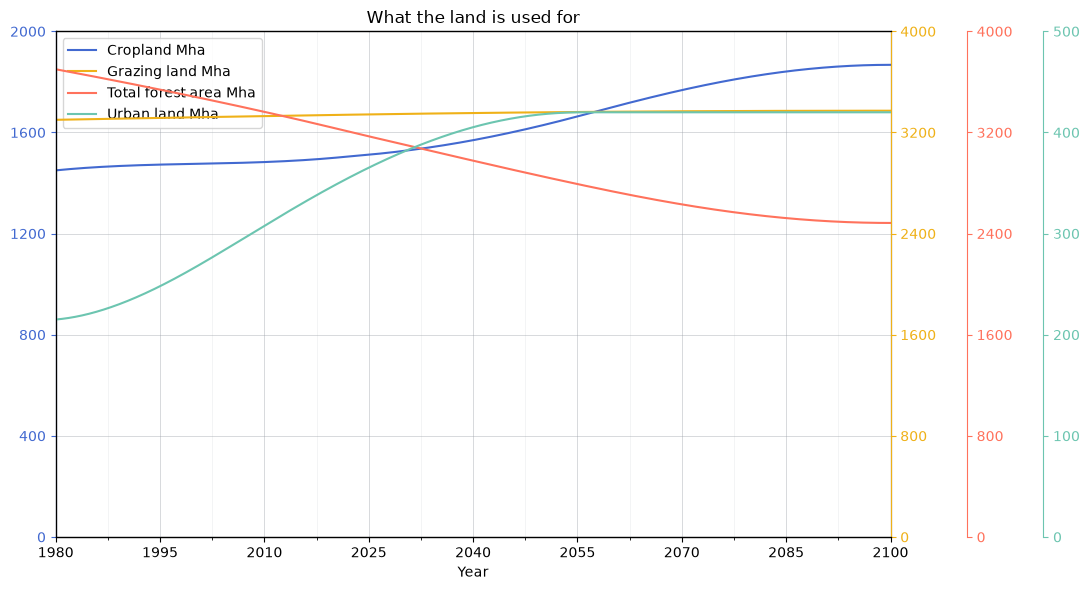

In [15]:
from earth4all.system import solve

solution = solve(earth4all.foodland.foodland_run(), (1980, 2100), dt=0.015625)

earth4all.plotvariables(
    solution,
    (1980, 2100),
    [
        (foodland.CRLA, 0, 2000, "Cropland Mha"),
        (foodland.GRLA, 0, 4000, "Grazing land Mha"),
        (foodland.TFA, 0, 4000, "Total forest area Mha"),
        (foodland.URLA, 0, 500, "Urban land Mha"),
    ],
    title="What the land is used for",
);

## Changing a sector

A sector takes its parameters as an argument, so a copy of them with a few
values changed is all a variant needs. Here the food turnaround of the *Giant
Leap* is switched on, in the food and land sector alone: less crop waste, more
regenerative agriculture, less red meat from feedlots.

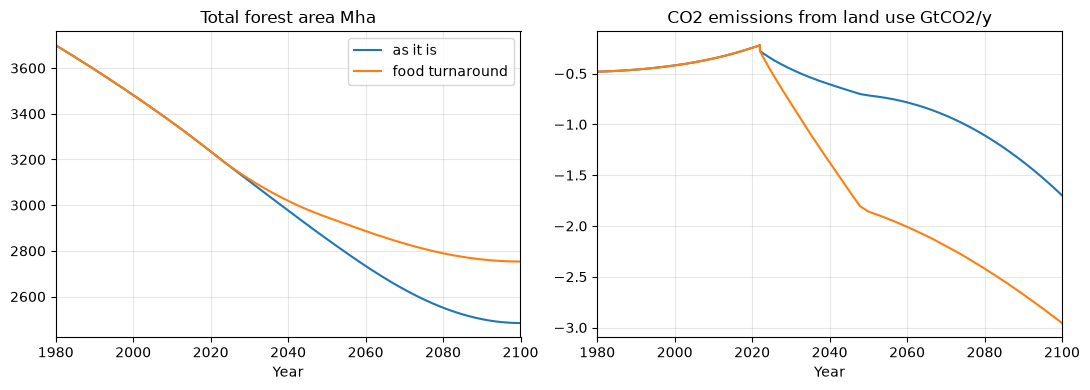

In [16]:
parameters = earth4all.foodland.getparameters()
parameters["GCWR"] = 0.2   # goal for crop waste reduction
parameters["GFRA"] = 0.5   # goal for fraction regenerative agriculture
parameters["GFNRM"] = 0.5  # goal for fraction new red meat

turnaround = solve(
    earth4all.foodland.foodland_run(params=parameters), (1980, 2100), dt=0.015625
)

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, run in [("as it is", solution), ("food turnaround", turnaround)]:
    axes[0].plot(run.t, run["foo.TFA"], label=label)
    axes[1].plot(run.t, run["foo.CO2ELULUC"], label=label)
axes[0].set_title("Total forest area Mha")
axes[1].set_title("CO2 emissions from land use GtCO2/y")
for panel in axes:
    panel.set_xlim(1980, 2100)
    panel.set_xlabel("Year")
    panel.grid(alpha=0.3)
axes[0].legend()
figure.tight_layout();

The whole-model version of this is `examples/two-scenarios.ipynb`, where the
five turnarounds are switched on together.